In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

In [2]:
class Problem:
    def __init__(self, path="../TSPA.csv"):
        self.df = pd.read_csv(path, sep=";", header=None)

        cord = self.df.values[:, :-1]
        dist = np.sqrt(np.sum((cord[None, :, :] - cord[:, None, :]) ** 2, axis=2))

        self.dist = np.floor(dist + 0.5).astype(np.int64)
        self.cost = np.ascontiguousarray(self.df.values[:, -1], dtype=np.int64)

    def get_n(self):
        return len(self.df)

    def get_n_nodes(self):
        # 50% of the nodes, rounded up
        return (self.get_n() + 1) // 2

    def eval(self, nodes: np.array, end=True):
        assert nodes.dtype == np.int64
        assert len(set(nodes)) == len(nodes)

        n_nodes = self.get_n_nodes()
        if end == True and len(nodes) != n_nodes:
            raise ValueError("The final path does not have the required length!")

        pairs = np.column_stack((nodes, np.roll(nodes, -1)))
        if not end:
            pairs = pairs[:-1]
        total_length = np.sum(self.dist[pairs[:, 0], pairs[:, 1]])
        total_cost = np.sum(self.cost[nodes])

        return total_length + total_cost


## Construction heuristics from assignments 1 and 2

The same algorithms as before (same solutions, same tie breaking), rewritten with numba so that the running times of all methods are comparable. NN (any position), greedy cycle and both regret heuristics use one function, as in assignment 2:

`score = w_regret * regret - w_greedy * best_delta`, the node with the highest score is inserted at its best position (ties: smaller best delta, then lower node index).

In [3]:
BIG = 1 << 62


def random_solution(n, n_nodes):
    return np.random.choice(n, size=n_nodes, replace=False)


@njit
def nearest_neighbor_end(d, cost, start, n_nodes):
    n = len(cost)
    path = np.empty(n_nodes, dtype=np.int64)
    used = np.zeros(n, dtype=np.bool_)
    path[0] = start
    used[start] = True

    for size in range(1, n_nodes):
        last = path[size - 1]
        best, best_j = BIG, -1
        for j in range(n):
            if not used[j] and d[last, j] + cost[j] < best:
                best, best_j = d[last, j] + cost[j], j
        path[size] = best_j
        used[best_j] = True

    return path


@njit
def regret_heuristic(d, cost, start, n_nodes, cycle, w_regret, w_greedy):
    n = len(cost)
    sol = np.empty(n_nodes, dtype=np.int64)
    used = np.zeros(n, dtype=np.bool_)
    sol[0] = start
    used[start] = True
    size = 1

    if cycle:
        # same start as greedy cycle: the second node closes a 2-node cycle
        best, second = BIG, -1
        for j in range(n):
            if j != start and 2 * d[start, j] + cost[j] < best:
                best, second = 2 * d[start, j] + cost[j], j
        sol[1] = second
        used[second] = True
        size = 2

    while size < n_nodes:
        best_score, best_delta, best_j, best_pos = -np.inf, BIG, -1, -1

        for j in range(n):
            if used[j]:
                continue

            # best and second best insertion cost of node j
            b1, b2, pos1 = BIG, BIG, -1
            n_pos = size if cycle else size + 1
            for i in range(n_pos):
                if cycle:
                    a, b = sol[i - 1] if i > 0 else sol[size - 1], sol[i]
                    delta = d[a, j] + d[j, b] - d[a, b]
                elif i == 0:
                    delta = d[j, sol[0]]
                elif i == size:
                    delta = d[sol[size - 1], j]
                else:
                    a, b = sol[i - 1], sol[i]
                    delta = d[a, j] + d[j, b] - d[a, b]
                delta += cost[j]

                if delta < b1:
                    b1, b2, pos1 = delta, b1, i
                elif delta < b2:
                    b2 = delta
            if n_pos == 1:
                b2 = b1

            score = w_regret * (b2 - b1) - w_greedy * b1
            if score > best_score or (score == best_score and b1 < best_delta):
                best_score, best_delta, best_j, best_pos = score, b1, j, pos1

        sol[best_pos + 1:size + 1] = sol[best_pos:size].copy()
        sol[best_pos] = best_j
        used[best_j] = True
        size += 1

    return sol


def nearest_neighbor_any(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, False, 0.0, 1.0)

def greedy_cycle(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, True, 0.0, 1.0)

def regret_nn_any(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, False, 1.0, 0.0)

def regret_greedy_cycle(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, True, 1.0, 0.0)

def weighted_regret_nn_any(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, False, 1.0, 1.0)

def weighted_regret_greedy_cycle(d, cost, start, n_nodes):
    return regret_heuristic(d, cost, start, n_nodes, True, 1.0, 1.0)


constructions = {
    "NN (end only)": nearest_neighbor_end,
    "NN (any position)": nearest_neighbor_any,
    "Greedy cycle": greedy_cycle,
    "2-regret (NN any position)": regret_nn_any,
    "2-regret (greedy cycle)": regret_greedy_cycle,
    "Weighted 2-regret (NN any position)": weighted_regret_nn_any,
    "Weighted 2-regret (greedy cycle)": weighted_regret_greedy_cycle,
}

## Moves and deltas

A solution is kept as two arrays: `sol` - the cycle (selected nodes in order) and `unsel` - the nodes that are not selected. A move is evaluated only by its delta (change of the objective), the neighbor solution is never built.

- Inter-route move `(i, k)`: replace the selected node `sol[i]` with the not selected node `unsel[k]` (at the same place in the cycle). Two edges and the node cost change.
- Intra-route two-nodes exchange `(i, j)`: swap the nodes at positions `i < j`. Four edges change (two if the nodes are neighbours, also the last and the first node).
- Intra-route two-edges exchange `(i, j)`: remove edges `(sol[i], sol[i+1])` and `(sol[j], sol[j+1])`, add `(sol[i], sol[j])` and `(sol[i+1], sol[j+1])`, i.e. reverse `sol[i+1..j]`. Pairs of edges with a common node are skipped (they give the same solution).

In [4]:
@njit
def delta_inter(d, cost, sol, unsel, i, k):
    n = len(sol)
    p, u, nx, v = sol[i - 1], sol[i], sol[(i + 1) % n], unsel[k]
    return d[p, v] + d[v, nx] - d[p, u] - d[u, nx] + cost[v] - cost[u]


@njit
def delta_two_nodes(d, sol, i, j):
    n = len(sol)
    a, b = sol[i], sol[j]
    if j == i + 1:
        p, nx = sol[i - 1], sol[(j + 1) % n]
        return d[p, b] + d[a, nx] - d[p, a] - d[b, nx]
    if i == 0 and j == n - 1:
        # b is right before a in the cycle
        p, nx = sol[j - 1], sol[i + 1]
        return d[p, a] + d[b, nx] - d[p, b] - d[a, nx]
    pa, na, pb, nb = sol[i - 1], sol[i + 1], sol[j - 1], sol[(j + 1) % n]
    return (d[pa, b] + d[b, na] + d[pb, a] + d[a, nb]
            - d[pa, a] - d[a, na] - d[pb, b] - d[b, nb])


@njit
def delta_two_edges(d, sol, i, j):
    n = len(sol)
    a1, a2, b1, b2 = sol[i], sol[i + 1], sol[j], sol[(j + 1) % n]
    return d[a1, b1] + d[a2, b2] - d[a1, a2] - d[b1, b2]


@njit
def delta_intra(d, sol, i, j, edges):
    if edges:
        return delta_two_edges(d, sol, i, j)
    return delta_two_nodes(d, sol, i, j)


@njit
def apply_intra(sol, i, j, edges):
    if edges:
        sol[i + 1:j + 1] = sol[i + 1:j + 1][::-1].copy()
    else:
        sol[i], sol[j] = sol[j], sol[i]


def intra_moves(n_nodes, edges):
    # all pairs of positions (i, j), i < j
    pairs = [(i, j) for i in range(n_nodes) for j in range(i + 1, n_nodes)]
    if edges:
        # two edges with a common node - not a real exchange
        pairs = [(i, j) for i, j in pairs if j >= i + 2 and not (i == 0 and j == n_nodes - 1)]
    pairs = np.array(pairs, dtype=np.int64)
    return pairs[:, 0].copy(), pairs[:, 1].copy()

## Local search

Both versions return the number of performed moves, the number of evaluated moves and the sum of the deltas of the performed moves (used to check that the deltas are correct).

**Steepest**: in each iteration all moves (inter-route and intra-route together) are evaluated and the best one is performed, as long as it improves the solution.

**Greedy**: all moves (inter-route and intra-route together) are indexed by one number `0 .. n_moves - 1`. The moves are browsed in a random order generated lazily with the Fisher-Yates shuffle: in step `t` we draw a random position `r` from `t .. n_moves - 1`, swap `order[t]` and `order[r]` and evaluate the move `order[t]`. So we only draw moves that we really evaluate, and the first improving move is performed at once. Then the browsing starts again with a new random order. Both kinds of moves are mixed in one order, so no kind is preferred. The local search stops when all moves were evaluated and none of them improves the solution.

In [5]:
@njit
def steepest_ls(d, cost, sol, unsel, move_i, move_j, edges, seed):
    n, m = len(sol), len(unsel)
    iters, evals, total = 0, 0, 0

    while True:
        best, kind, bi, bj = 0, -1, 0, 0
        for i in range(n):
            for k in range(m):
                delta = delta_inter(d, cost, sol, unsel, i, k)
                if delta < best:
                    best, kind, bi, bj = delta, 0, i, k
        for q in range(len(move_i)):
            delta = delta_intra(d, sol, move_i[q], move_j[q], edges)
            if delta < best:
                best, kind, bi, bj = delta, 1, move_i[q], move_j[q]
        evals += n * m + len(move_i)

        if kind == -1:
            return iters, evals, total
        if kind == 0:
            sol[bi], unsel[bj] = unsel[bj], sol[bi]
        else:
            apply_intra(sol, bi, bj, edges)
        iters += 1
        total += best


@njit
def greedy_ls(d, cost, sol, unsel, move_i, move_j, edges, seed):
    np.random.seed(seed)
    n, m = len(sol), len(unsel)
    n_inter = n * m
    n_moves = n_inter + len(move_i)
    # moves 0 .. n_inter - 1 are inter-route, the rest are intra-route
    order = np.arange(n_moves)
    iters, evals, total = 0, 0, 0

    while True:
        found = False
        for t in range(n_moves):
            # lazy Fisher-Yates shuffle
            r = np.random.randint(t, n_moves)
            move = order[r]
            order[r] = order[t]
            order[t] = move
            evals += 1

            if move < n_inter:
                i, k = move // m, move % m
                delta = delta_inter(d, cost, sol, unsel, i, k)
                if delta < 0:
                    sol[i], unsel[k] = unsel[k], sol[i]
                    found = True
            else:
                i, j = move_i[move - n_inter], move_j[move - n_inter]
                delta = delta_intra(d, sol, i, j, edges)
                if delta < 0:
                    apply_intra(sol, i, j, edges)
                    found = True

            if found:
                iters += 1
                total += delta
                break

        if not found:
            return iters, evals, total

## Experiment

All methods are timed in the same way (numba, compiled before the measurements). For the local search the running time includes building the starting solution.

Greedy starting solutions use the best construction heuristic for each instance (the lowest mean objective in the table below), started from every node. Random starting solutions are the same 200 random solutions as in the "Random" row.

In [6]:
problems = {name: Problem(f"../{name}.csv") for name in ["TSPA", "TSPB"]}

# compile all numba functions before the measurements
p = problems["TSPA"]
k = p.get_n_nodes()
for f in constructions.values():
    f(p.dist, p.cost, 0, k)
for edges in [False, True]:
    move_i, move_j = intra_moves(k, edges)
    for ls in [steepest_ls, greedy_ls]:
        sol = random_solution(p.get_n(), k)
        ls(p.dist, p.cost, sol, np.setdiff1d(np.arange(p.get_n()), sol), move_i, move_j, edges, 0)

In [7]:
np.random.seed(0)
results = {}
random_solutions = {}

for name, p in problems.items():
    n, k = p.get_n(), p.get_n_nodes()

    values, times, sols = [], [], []
    for _ in range(200):
        t0 = time.perf_counter()
        s = random_solution(n, k)
        times.append(time.perf_counter() - t0)
        values.append(p.eval(s))
        sols.append(s)
    random_solutions[name] = sols
    results[("Random", name)] = {"values": np.array(values), "times": np.array(times), "best": sols[int(np.argmin(values))]}

    for method, f in constructions.items():
        values, times, sols = [], [], []
        for start in range(n):
            t0 = time.perf_counter()
            s = f(p.dist, p.cost, start, k)
            times.append(time.perf_counter() - t0)
            values.append(p.eval(s))
            sols.append(s)
        results[(method, name)] = {"values": np.array(values), "times": np.array(times), "best": sols[int(np.argmin(values))]}

best_construction = {
    name: min(constructions, key=lambda m: results[(m, name)]["values"].mean())
    for name in problems
}
best_construction

{'TSPA': 'Weighted 2-regret (greedy cycle)',
 'TSPB': 'Weighted 2-regret (NN any position)'}

In [8]:
local_searches = {"Steepest": steepest_ls, "Greedy": greedy_ls}
intra_types = {"two-nodes": False, "two-edges": True}
start_types = ["random", "greedy"]
ls_methods = [
    (ls, intra, start)
    for ls in local_searches for intra in intra_types for start in start_types
]


def ls_label(ls, intra, start):
    return f"{ls} LS, {intra} exchange, {start} start"


for name, p in problems.items():
    n, k = p.get_n(), p.get_n_nodes()
    construction = constructions[best_construction[name]]

    for ls, intra, start in ls_methods:
        edges = intra_types[intra]
        move_i, move_j = intra_moves(k, edges)
        values, times, sols, iters, evals = [], [], [], [], []

        for run in range(200):
            t0 = time.perf_counter()
            if start == "random":
                sol = random_solutions[name][run].copy()
            else:
                sol = construction(p.dist, p.cost, run, k)
            unsel = np.setdiff1d(np.arange(n), sol)
            t1 = time.perf_counter()
            start_value = p.eval(sol)

            t2 = time.perf_counter()
            it, ev, total = local_searches[ls](p.dist, p.cost, sol, unsel, move_i, move_j, edges, run)
            t3 = time.perf_counter()

            value = p.eval(sol)
            # the sum of the deltas must match the objective computed from scratch
            assert value == start_value + total
            values.append(value)
            times.append((t1 - t0) + (t3 - t2))
            sols.append(sol)
            iters.append(it)
            evals.append(ev)

        results[(ls_label(ls, intra, start), name)] = {
            "values": np.array(values), "times": np.array(times), "best": sols[int(np.argmin(values))],
            "iters": np.array(iters), "evals": np.array(evals),
        }

## Results

In [9]:
methods = ["Random"] + list(constructions) + [ls_label(*m) for m in ls_methods]


def summary(key, fmt_mean, fmt_range):
    # av (min – max) for each instance
    rows = []
    for method in methods:
        row = {"Method": method}
        for name in problems:
            v = results[(method, name)][key]
            row[name] = f"{fmt_mean(v.mean())} ({fmt_range(v.min())} – {fmt_range(v.max())})"
        rows.append(row)
    return pd.DataFrame(rows)


objective_table = summary("values", lambda x: f"{np.round(x, 2):.2f}", lambda x: f"{x}")
objective_table

,Method,TSPA,TSPB
0,Random,262874.39 (238989 – 290456),206009.68 (185119 – 225987)
1,NN (end only),87476.63 (84362 – 90075),59397.34 (56007 – 63166)
2,NN (any position),74346.96 (72328 – 77022),59475.50 (52915 – 66164)
3,Greedy cycle,73792.87 (72590 – 75345),59777.50 (55655 – 63736)
4,2-regret (NN any position),121360.29 (110950 – 135771),73649.84 (68761 – 79756)
5,2-regret (greedy cycle),120378.76 (112806 – 128089),72484.84 (68150 – 77274)
6,Weighted 2-regret (NN any position),75549.36 (72419 – 78504),55698.94 (50485 – 61406)
7,Weighted 2-regret (greedy cycle),73349.74 (72011 – 75532),57766.23 (52906 – 63326)
8,"Steepest LS, two-nodes exchange, random start",90055.08 (82625 – 101632),65763.93 (58035 – 72736)
9,"Steepest LS, two-nodes exchange, greedy start",73018.38 (71955 – 74861),54292.94 (49978 – 61265)


In [10]:
# running time in milliseconds
ms = lambda x: f"{1000 * x:.3f}"
time_table = summary("times", ms, ms)
time_table

,Method,TSPA,TSPB
0,Random,0.007 (0.005 – 0.050),0.007 (0.006 – 0.042)
1,NN (end only),0.016 (0.013 – 0.031),0.015 (0.013 – 0.024)
2,NN (any position),0.978 (0.954 – 1.098),0.982 (0.962 – 1.013)
3,Greedy cycle,0.871 (0.854 – 0.990),0.872 (0.854 – 0.900)
4,2-regret (NN any position),0.976 (0.959 – 1.024),0.997 (0.963 – 1.772)
5,2-regret (greedy cycle),0.878 (0.852 – 1.003),0.882 (0.855 – 0.957)
6,Weighted 2-regret (NN any position),0.985 (0.962 – 1.018),0.992 (0.976 – 1.016)
7,Weighted 2-regret (greedy cycle),0.879 (0.852 – 0.905),0.877 (0.859 – 0.905)
8,"Steepest LS, two-nodes exchange, random start",21.345 (17.668 – 29.358),20.824 (16.516 – 26.492)
9,"Steepest LS, two-nodes exchange, greedy start",1.516 (1.043 – 2.295),2.620 (1.229 – 4.372)


In [11]:
# average number of performed moves and of evaluated moves
rows = []
for m in ls_methods:
    row = {"Method": ls_label(*m)}
    for name in problems:
        r = results[(ls_label(*m), name)]
        row[f"{name} moves"] = round(r["iters"].mean(), 1)
        row[f"{name} evaluated"] = round(r["evals"].mean())
    rows.append(row)
moves_table = pd.DataFrame(rows)
moves_table

,Method,TSPA moves,TSPA evaluated,TSPB moves,TSPB evaluated
0,"Steepest LS, two-nodes exchange, random start",154.8,2328762,150.8,2269784
1,"Steepest LS, two-nodes exchange, greedy start",3.3,64659,10.5,171327
2,"Steepest LS, two-edges exchange, random start",133.0,1990568,132.8,1987450
3,"Steepest LS, two-edges exchange, greedy start",3.3,63706,14.3,227205
4,"Greedy LS, two-nodes exchange, random start",418.2,143928,415.9,134677
5,"Greedy LS, two-nodes exchange, greedy start",4.3,33088,15.4,53172
6,"Greedy LS, two-edges exchange, random start",417.9,96980,418.1,96878
7,"Greedy LS, two-edges exchange, greedy start",4.5,33244,26.3,63418


## Solution check

Independent check of the best solutions: the right number of distinct nodes, the objective recomputed from scratch with plain loops, and for the local search methods - that the solution is really a local optimum. Every neighbor solution is built explicitly (all pairs of positions, all not selected nodes) and its objective is computed from scratch, without the delta functions and the move lists used by the local search.

In [12]:
def objective_from_scratch(p, nodes):
    nodes = [int(x) for x in nodes]
    length = sum(p.dist[nodes[i], nodes[(i + 1) % len(nodes)]] for i in range(len(nodes)))
    return length + sum(p.cost[x] for x in nodes)


def is_local_optimum(p, sol, edges):
    # all neighbors are built explicitly, without the delta functions and the move lists of the local search
    value = objective_from_scratch(p, sol)
    for i in range(len(sol)):
        for v in range(p.get_n()):
            if v in sol:
                continue
            s = sol.copy()
            s[i] = v
            if objective_from_scratch(p, s) < value:
                return False
    for i in range(len(sol)):
        for j in range(i + 1, len(sol)):
            s = sol.copy()
            if edges:
                s[i + 1:j + 1] = s[i + 1:j + 1][::-1]
            else:
                s[i], s[j] = s[j], s[i]
            if objective_from_scratch(p, s) < value:
                return False
    return True


for (method, name), r in results.items():
    p, s = problems[name], r["best"]
    assert len(s) == p.get_n_nodes() and len(set(s.tolist())) == len(s)
    assert all(0 <= x < p.get_n() for x in s)
    assert objective_from_scratch(p, s) == r["values"].min()

for ls, intra, start in ls_methods:
    for name, p in problems.items():
        assert is_local_optimum(p, results[(ls_label(ls, intra, start), name)]["best"], intra_types[intra])
print("All best solutions are valid, the local search solutions are local optima")

All best solutions are valid, the local search solutions are local optima


## Visualization

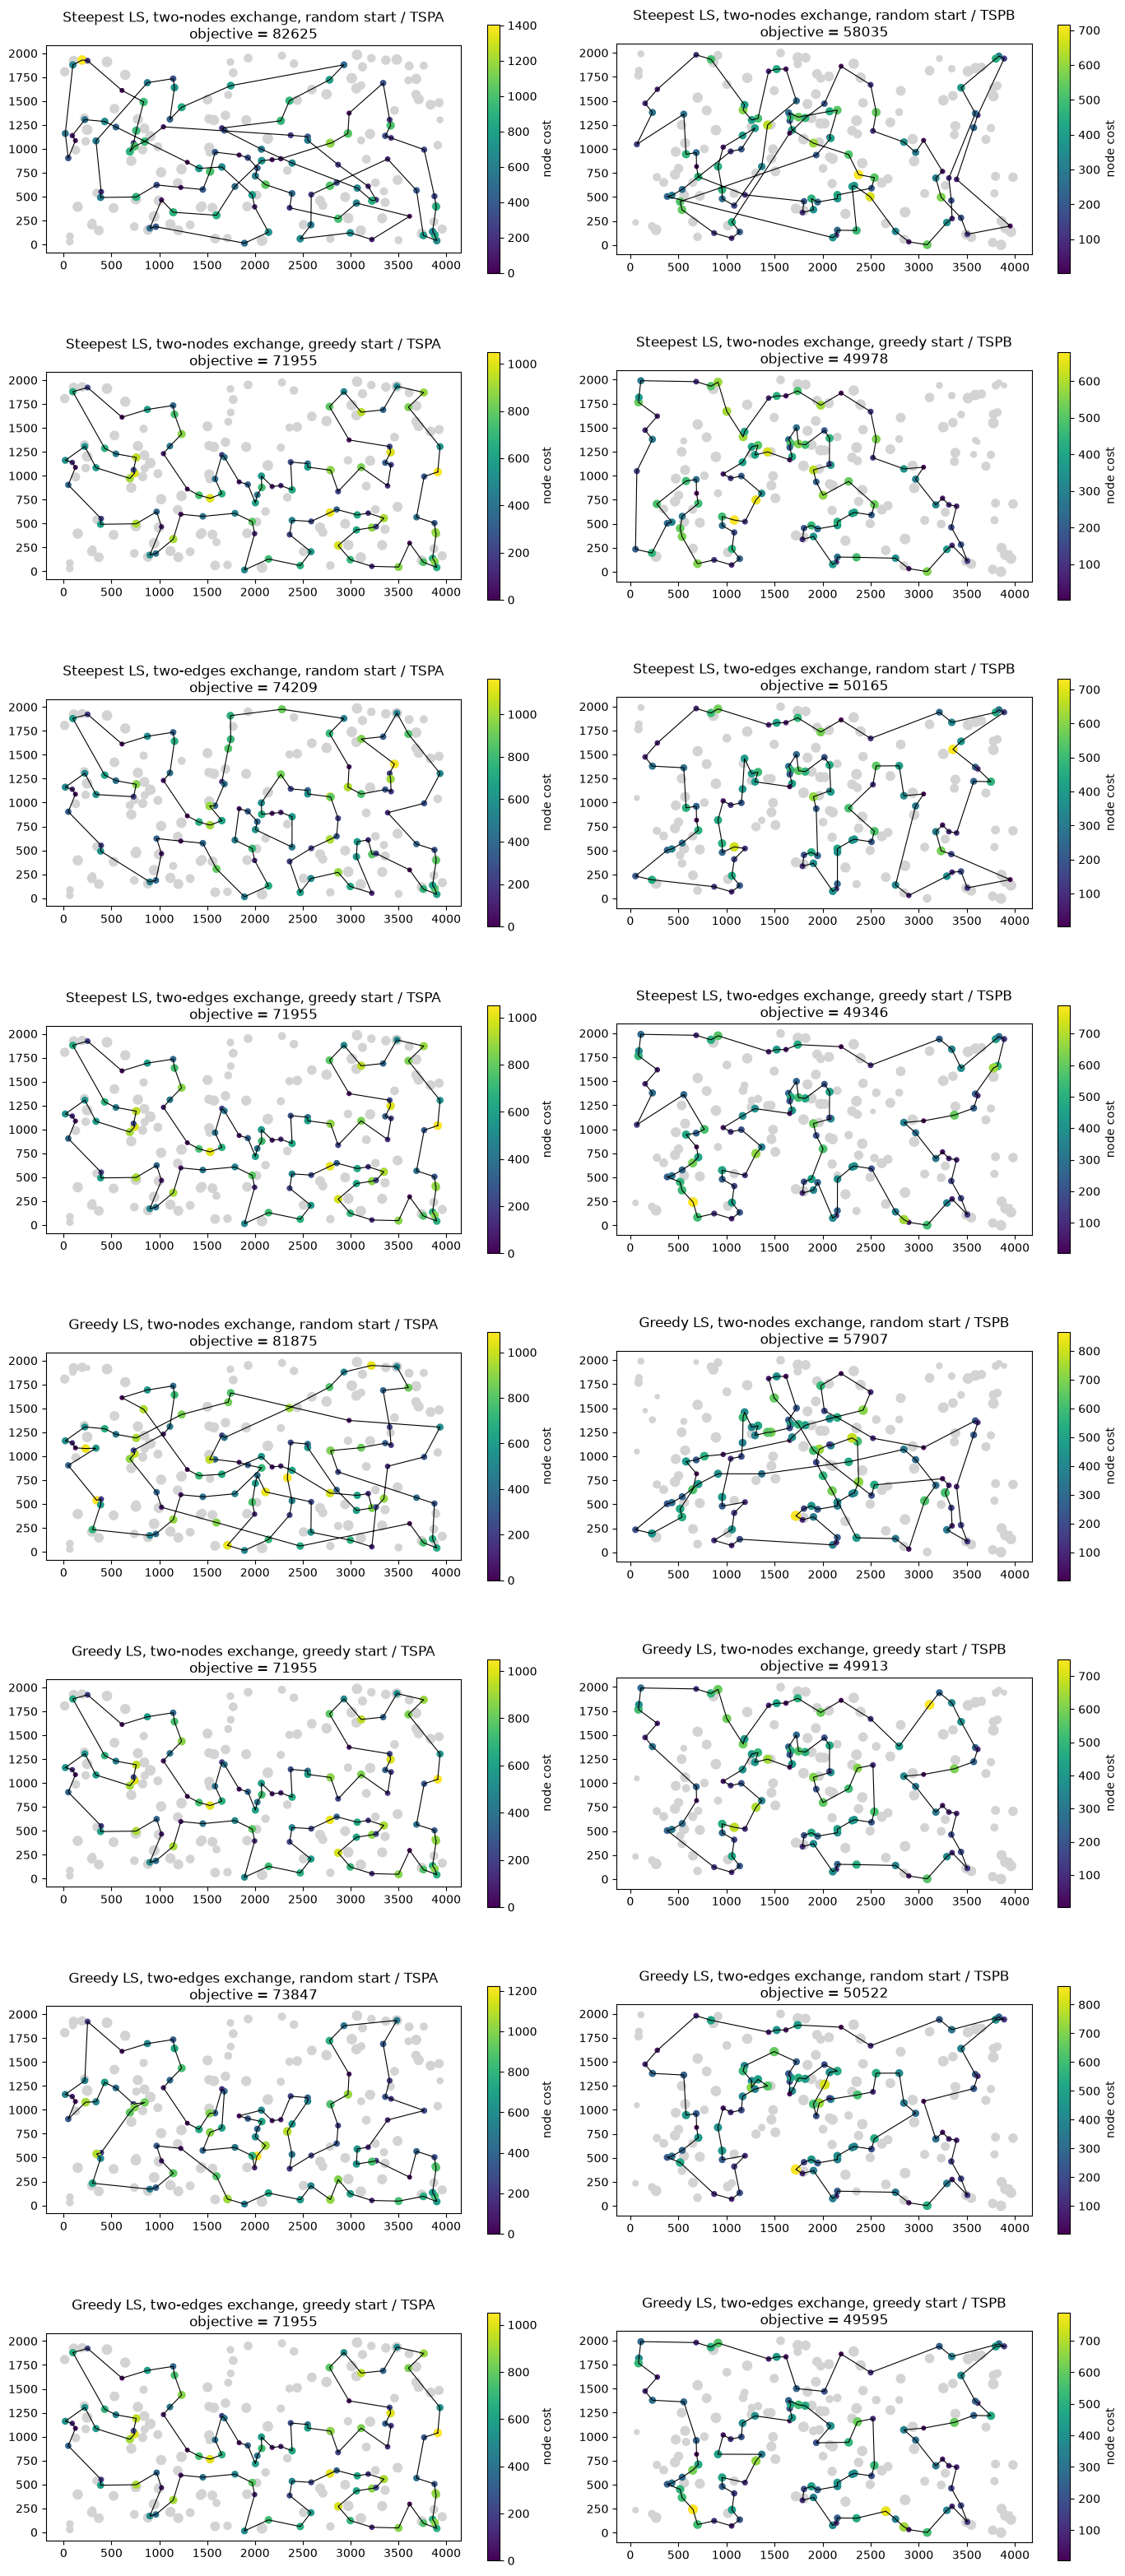

In [13]:
ls_names = [ls_label(*m) for m in ls_methods]
fig, axes = plt.subplots(len(ls_names), len(problems), figsize=(7 * len(problems), 4 * len(ls_names)), squeeze=False)

for col, (name, p) in enumerate(problems.items()):
    x, y, cost = p.df[0].values, p.df[1].values, p.df[2].values
    sizes = 10 + 60 * cost / cost.max()

    for row, method in enumerate(ls_names):
        ax = axes[row, col]
        solution = results[(method, name)]["best"]
        cycle = np.append(solution, solution[0])

        # all nodes in gray, selected nodes colored by cost, size also by cost
        ax.scatter(x, y, s=sizes, c="lightgray")
        ax.plot(x[cycle], y[cycle], c="black", linewidth=0.8)
        points = ax.scatter(x[solution], y[solution], s=sizes[solution], c=cost[solution], cmap="viridis")

        ax.set_title(f"{method} / {name}\nobjective = {p.eval(solution)}")
        ax.set_aspect("equal")
        fig.colorbar(points, ax=ax, label="node cost", shrink=0.8)

fig.tight_layout()
fig.savefig("solutions.png", dpi=100)
plt.show()

## Best solutions

In [14]:
for method in ls_names:
    for name, p in problems.items():
        s = results[(method, name)]["best"]
        print(f"{method} / {name} ({p.eval(s)}):")
        print(", ".join(str(x) for x in s))
        print()

Steepest LS, two-nodes exchange, random start / TSPA (82625):
108, 60, 149, 63, 168, 116, 31, 7, 48, 80, 38, 100, 123, 160, 83, 90, 132, 33, 9, 54, 174, 106, 89, 42, 150, 131, 52, 16, 51, 143, 62, 186, 136, 112, 4, 76, 71, 157, 91, 49, 97, 127, 161, 30, 141, 87, 102, 35, 67, 144, 53, 140, 41, 84, 58, 138, 151, 107, 57, 182, 192, 158, 134, 72, 176, 93, 130, 88, 78, 193, 153, 170, 159, 47, 50, 3, 169, 1, 178, 164, 142, 8, 194, 36, 177, 179, 45, 98, 189, 187, 171, 2, 114, 181, 135, 73, 185, 28, 180, 152

Steepest LS, two-nodes exchange, random start / TSPB (58035):
167, 181, 152, 67, 66, 11, 27, 122, 160, 172, 136, 133, 8, 46, 86, 184, 3, 151, 197, 36, 175, 134, 45, 157, 69, 117, 72, 89, 57, 185, 76, 162, 192, 54, 127, 80, 182, 14, 2, 110, 90, 10, 114, 105, 94, 81, 187, 196, 129, 153, 20, 74, 17, 171, 99, 31, 24, 34, 88, 179, 87, 82, 132, 29, 6, 140, 47, 21, 38, 154, 97, 155, 71, 60, 64, 189, 120, 96, 198, 121, 183, 30, 191, 130, 147, 116, 149, 28, 145, 65, 158, 177, 125, 170, 115, 40, 59